Hola **Mara**!

Soy **Patricio Requena** 👋. Es un placer ser el revisor de tu proyecto el día de hoy!

Revisaré tu proyecto detenidamente con el objetivo de ayudarte a mejorar y perfeccionar tus habilidades. Durante mi revisión, identificaré áreas donde puedas hacer mejoras en tu código, señalando específicamente qué y cómo podrías ajustar para optimizar el rendimiento y la claridad de tu proyecto. Además, es importante para mí destacar los aspectos que has manejado excepcionalmente bien. Reconocer tus fortalezas te ayudará a entender qué técnicas y métodos están funcionando a tu favor y cómo puedes aplicarlos en futuras tareas. 

_**Recuerda que al final de este notebook encontrarás un comentario general de mi parte**_, empecemos!

Encontrarás mis comentarios dentro de cajas verdes, amarillas o rojas, ⚠️ **por favor, no muevas, modifiques o borres mis comentarios** ⚠️:


<div class="alert alert-block alert-success">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si todo está perfecto.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si tu código está bien pero se puede mejorar o hay algún detalle que le hace falta.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor</b> <a class=“tocSkip”></a>
Si de pronto hace falta algo o existe algún problema con tu código o conclusiones.
</div>

Puedes responderme de esta forma:
<div class="alert alert-block alert-info">
<b>Respuesta del estudiante</b> <a class=“tocSkip”></a>
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Para seguir buenas prácticas y tener una correcta presentación de tus notebooks te recomiendo siempre al inicio del notebook dejar en una celda markdown un título y una breve introducción al proyecto.

Recuerda que las celdas markdown ayudan a dejar el proceso de análisis claro en el notebook por lo que se debe hacer más uso de estas.
</div>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/datasets/logs_exp_us.csv', sep='\t')
print(df.head())
print(f"\nForma: {df.shape}")
print(f"\nColumnas: {df.columns.tolist()}")
print(f"\nTipos:\n{df.dtypes}")

                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248

Forma: (244126, 4)

Columnas: ['EventName', 'DeviceIDHash', 'EventTimestamp', 'ExpId']

Tipos:
EventName         object
DeviceIDHash       int64
EventTimestamp     int64
ExpId              int64
dtype: object


In [3]:
# Renombrar columnas
df.columns = ['event_name', 'user_id', 'timestamp', 'exp_id']

# Convertir timestamp a datetime
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')

# Columna de solo fecha
df['date'] = df['datetime'].dt.date

# Verificar nulos
print(f"Valores ausentes:\n{df.isnull().sum()}")
print(f"\nTipos de datos:\n{df.dtypes}")
print(f"\nMuestra:\n{df.head()}")

Valores ausentes:
event_name    0
user_id       0
timestamp     0
exp_id        0
datetime      0
date          0
dtype: int64

Tipos de datos:
event_name            object
user_id                int64
timestamp              int64
exp_id                 int64
datetime      datetime64[ns]
date                  object
dtype: object

Muestra:
                event_name              user_id   timestamp  exp_id  \
0         MainScreenAppear  4575588528974610257  1564029816     246   
1         MainScreenAppear  7416695313311560658  1564053102     246   
2  PaymentScreenSuccessful  3518123091307005509  1564054127     248   
3         CartScreenAppear  3518123091307005509  1564054127     248   
4  PaymentScreenSuccessful  6217807653094995999  1564055322     248   

             datetime        date  
0 2019-07-25 04:43:36  2019-07-25  
1 2019-07-25 11:11:42  2019-07-25  
2 2019-07-25 11:28:47  2019-07-25  
3 2019-07-25 11:28:47  2019-07-25  
4 2019-07-25 11:48:42  2019-07-25  


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy bien hecha la revisión inicial de los datos para tu análisis, siempre es importante revisar la calidad de tus datos y realizar las transformaciones necesarias 
</div>

In [4]:
# Totales generales
total_events = len(df)
total_users = df['user_id'].nunique()
avg_events = total_events / total_users

print(f"Total de eventos: {total_events:,}")
print(f"Total de usuarios: {total_users:,}")
print(f"Promedio eventos/usuario: {avg_events:.2f}")
print(f"\nFecha mínima: {df['datetime'].min()}")
print(f"Fecha máxima: {df['datetime'].max()}")

Total de eventos: 244,126
Total de usuarios: 7,551
Promedio eventos/usuario: 32.33

Fecha mínima: 2019-07-25 04:43:36
Fecha máxima: 2019-08-07 21:15:17


<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Correcto, aquí cómo recomendación para que le des un plus a tu análisis, es que este tipo de métricas cómo la del promedio de eventos de abajo las calcules por cada grupo cuando se trate de pruebas AB ya que así se puede ir viendo las diferencias desde el inicio.
</div>

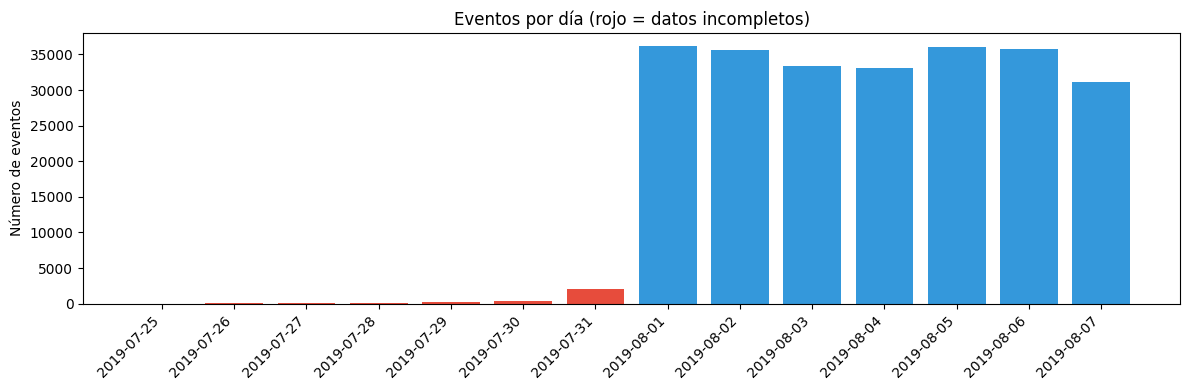


Eventos por día:
date
2019-07-25        9
2019-07-26       31
2019-07-27       55
2019-07-28      105
2019-07-29      184
2019-07-30      413
2019-07-31     2031
2019-08-01    36229
2019-08-02    35606
2019-08-03    33351
2019-08-04    33033
2019-08-05    36113
2019-08-06    35822
2019-08-07    31144


In [5]:
# Histograma de eventos por día para detectar datos incompletos
eventos_dia = df.groupby('date').size()

plt.figure(figsize=(12, 4))
colores = ['#e74c3c' if str(d) < '2019-08-01' else '#3498db' for d in eventos_dia.index]
plt.bar(range(len(eventos_dia)), eventos_dia.values, color=colores)
plt.xticks(range(len(eventos_dia)),
           [str(d) for d in eventos_dia.index],
           rotation=45, ha='right')
plt.title('Eventos por día (rojo = datos incompletos)')
plt.ylabel('Número de eventos')
plt.tight_layout()
plt.show()

print("\nEventos por día:")
print(eventos_dia.to_string())

In [6]:
# Aplicar corte desde el 1 de agosto (datos completos)
df_clean = df[df['datetime'] >= '2019-08-01'].copy()

eventos_perdidos = total_events - len(df_clean)
usuarios_perdidos = total_users - df_clean['user_id'].nunique()

print(f"Eventos tras corte: {len(df_clean):,}  (perdidos: {eventos_perdidos:,} = {eventos_perdidos/total_events*100:.1f}%)")
print(f"Usuarios tras corte: {df_clean['user_id'].nunique():,}  (perdidos: {usuarios_perdidos:,} = {usuarios_perdidos/total_users*100:.1f}%)")
print(f"\nPeríodo real de los datos: {df_clean['datetime'].min().date()} → {df_clean['datetime'].max().date()}")

Eventos tras corte: 241,298  (perdidos: 2,828 = 1.2%)
Usuarios tras corte: 7,534  (perdidos: 17 = 0.2%)

Período real de los datos: 2019-08-01 → 2019-08-07


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Buen trabajo con el filtro aplicado, de esta forma aseguras no tener "ruido" en tu muestra de datos
</div>

In [7]:
# Verificar que los 3 grupos experimentales están presentes
print("Usuarios por grupo experimental:")
print(df_clean.groupby('exp_id')['user_id'].nunique())

Usuarios por grupo experimental:
exp_id
246    2484
247    2513
248    2537
Name: user_id, dtype: int64


In [8]:
# Frecuencia de cada evento
print("Frecuencia de eventos:")
print(df_clean['event_name'].value_counts())

Frecuencia de eventos:
MainScreenAppear           117431
OffersScreenAppear          46350
CartScreenAppear            42365
PaymentScreenSuccessful     34113
Tutorial                     1039
Name: event_name, dtype: int64


In [9]:
# Usuarios únicos por evento
clean_users = df_clean['user_id'].nunique()
users_per_event = df_clean.groupby('event_name')['user_id'].nunique().sort_values(ascending=False)

print(f"Usuarios únicos por evento (total: {clean_users:,}):\n")
for event, count in users_per_event.items():
    pct = count / clean_users * 100
    print(f"  {event:<35} {count:>6,}  ({pct:.1f}%)")

Usuarios únicos por evento (total: 7,534):

  MainScreenAppear                     7,419  (98.5%)
  OffersScreenAppear                   4,593  (61.0%)
  CartScreenAppear                     3,734  (49.6%)
  PaymentScreenSuccessful              3,539  (47.0%)
  Tutorial                               840  (11.1%)


In [10]:
# Definir secuencia del embudo en orden lógico
EMBUDO = [
    'MainScreenAppear',
    'OffersScreenAppear',
    'CartScreenAppear',
    'PaymentScreenSuccessful',
]
LABELS = ['Pantalla Principal', 'Pantalla Ofertas', 'Pantalla Carrito', 'Pago Exitoso']

# Conversión etapa a etapa
print("Análisis de conversión en el embudo:\n")
prev = None
for e in EMBUDO:
    n = users_per_event.get(e, 0)
    pct_total = n / clean_users * 100
    if prev:
        pct_prev = n / prev * 100
        print(f"  {e:<35} {n:>6,}  ({pct_total:.1f}% total | {pct_prev:.1f}% del paso anterior)")
    else:
        print(f"  {e:<35} {n:>6,}  ({pct_total:.1f}% total)")
    prev = n

inicio = users_per_event.get(EMBUDO[0], 0)
fin    = users_per_event.get(EMBUDO[-1], 0)
print(f"\nConversión global: {fin/inicio*100:.1f}%")

Análisis de conversión en el embudo:

  MainScreenAppear                     7,419  (98.5% total)
  OffersScreenAppear                   4,593  (61.0% total | 61.9% del paso anterior)
  CartScreenAppear                     3,734  (49.6% total | 81.3% del paso anterior)
  PaymentScreenSuccessful              3,539  (47.0% total | 94.8% del paso anterior)

Conversión global: 47.7%


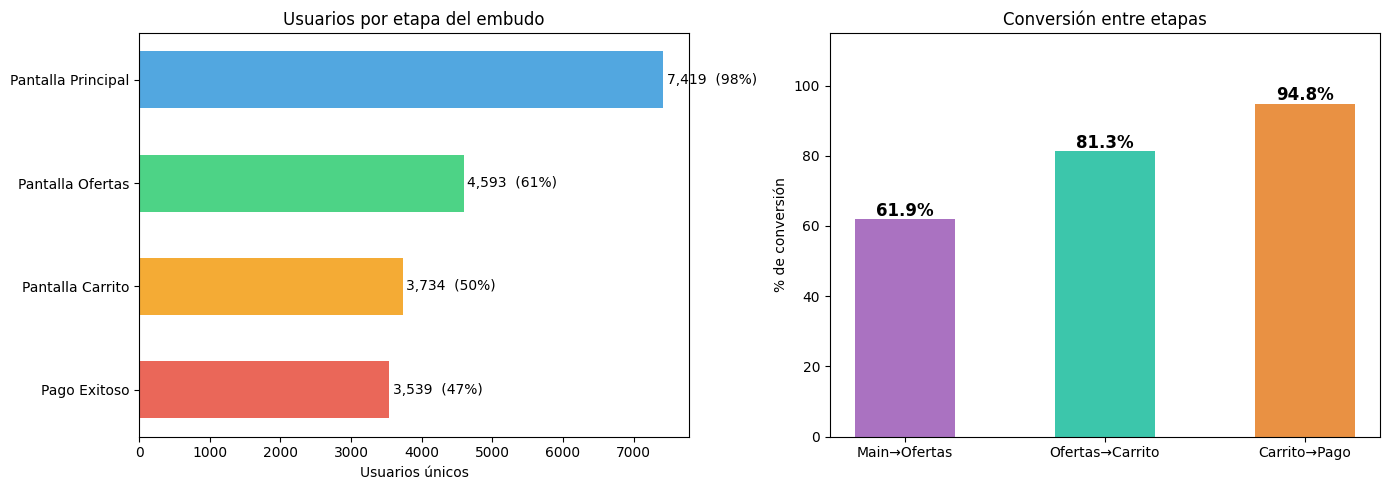

In [11]:
# Gráfica del embudo
valores = [users_per_event.get(e, 0) for e in EMBUDO]
colores_emb = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Barras horizontales
axes[0].barh(range(len(EMBUDO)), valores, color=colores_emb, alpha=0.85, height=0.55)
for i, val in enumerate(valores):
    axes[0].text(val + 50, i, f'{val:,}  ({val/clean_users*100:.0f}%)',
                 va='center', fontsize=10)
axes[0].set_yticks(range(len(EMBUDO)))
axes[0].set_yticklabels(LABELS)
axes[0].invert_yaxis()
axes[0].set_xlabel('Usuarios únicos')
axes[0].set_title('Usuarios por etapa del embudo')

# Conversión etapa a etapa
conversiones = []
for i in range(1, len(EMBUDO)):
    prev = users_per_event.get(EMBUDO[i-1], 1)
    curr = users_per_event.get(EMBUDO[i], 0)
    conversiones.append(curr / prev * 100)

etiquetas_conv = ['Main→Ofertas', 'Ofertas→Carrito', 'Carrito→Pago']
bars = axes[1].bar(etiquetas_conv, conversiones,
                   color=['#9b59b6', '#1abc9c', '#e67e22'], alpha=0.85, width=0.5)
for bar, val in zip(bars, conversiones):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.1f}%', ha='center', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('% de conversión')
axes[1].set_title('Conversión entre etapas')

plt.tight_layout()
plt.show()

<div class="alert alert-block alert-warning">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy bien hecho los cálculos de las conversiones! Al tratarse de una prueba AB puedes dejarlo en una visualización donde se observe cada grupo ayuda para que la comparación sea más visual y fácil de exponer
</div>

In [12]:
# Usuarios por grupo
print("Usuarios por grupo experimental (datos limpios):")
print(df_clean.groupby('exp_id')['user_id'].nunique())

Usuarios por grupo experimental (datos limpios):
exp_id
246    2484
247    2513
248    2537
Name: user_id, dtype: int64


In [13]:
# Función reutilizable de prueba z de proporciones
def test_proporciones(g_a, g_b, event, df, alpha=0.05):
    tot_a = df[df['exp_id'] == g_a]['user_id'].nunique()
    tot_b = df[df['exp_id'] == g_b]['user_id'].nunique()
    u_a = df[(df['exp_id'] == g_a) & (df['event_name'] == event)]['user_id'].nunique()
    u_b = df[(df['exp_id'] == g_b) & (df['event_name'] == event)]['user_id'].nunique()

    p_a = u_a / tot_a
    p_b = u_b / tot_b
    p_pool = (u_a + u_b) / (tot_a + tot_b)
    se = np.sqrt(p_pool * (1 - p_pool) * (1/tot_a + 1/tot_b))

    z = (p_a - p_b) / se if se > 0 else 0
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))

    sig = "⚠️  SIGNIFICATIVO" if p_value < alpha else "✅ No significativo"
    print(f"  {event:<35}  p_{g_a}={p_a:.3f}  p_{g_b}={p_b:.3f}  pval={p_value:.4f}  {sig}")
    return p_value

In [14]:
# Comparación A/A: 246 vs 247 (deben ser NO significativas)
ALPHA = 0.05
print(f"--- Validación A/A: Grupo 246 vs 247  (α={ALPHA}) ---\n")
for e in EMBUDO:
    test_proporciones(246, 247, e, df_clean, ALPHA)

--- Validación A/A: Grupo 246 vs 247  (α=0.05) ---

  MainScreenAppear                     p_246=0.986  p_247=0.985  pval=0.7571  ✅ No significativo
  OffersScreenAppear                   p_246=0.621  p_247=0.605  pval=0.2481  ✅ No significativo
  CartScreenAppear                     p_246=0.510  p_247=0.493  pval=0.2288  ✅ No significativo
  PaymentScreenSuccessful              p_246=0.483  p_247=0.461  pval=0.1146  ✅ No significativo


In [15]:
# Comparación A/A: 246 vs 247 (deben ser NO significativas)
ALPHA = 0.05
print(f"--- Validación A/A: Grupo 246 vs 247  (α={ALPHA}) ---\n")
for e in EMBUDO:
    test_proporciones(246, 247, e, df_clean, ALPHA)

--- Validación A/A: Grupo 246 vs 247  (α=0.05) ---

  MainScreenAppear                     p_246=0.986  p_247=0.985  pval=0.7571  ✅ No significativo
  OffersScreenAppear                   p_246=0.621  p_247=0.605  pval=0.2481  ✅ No significativo
  CartScreenAppear                     p_246=0.510  p_247=0.493  pval=0.2288  ✅ No significativo
  PaymentScreenSuccessful              p_246=0.483  p_247=0.461  pval=0.1146  ✅ No significativo


<div class="alert alert-block alert-success">
<b>Comentario del revisor (1ra Iteracion)</b> <a class=“tocSkip”></a>

Muy bien! Siempre es bueno aplicar pruebas estadísticas a cada etapa del embudo para entender si en alguna parte el comportamiento de los usuarios ha cambiado 
</div>

In [16]:
# Grupo 246 (control) vs 248 (prueba)
print(f"--- Grupo 246 vs 248 (nueva fuente)  (α={ALPHA}) ---\n")
for e in EMBUDO:
    test_proporciones(246, 248, e, df_clean, ALPHA)

--- Grupo 246 vs 248 (nueva fuente)  (α=0.05) ---

  MainScreenAppear                     p_246=0.986  p_248=0.983  pval=0.2950  ✅ No significativo
  OffersScreenAppear                   p_246=0.621  p_248=0.603  pval=0.2084  ✅ No significativo
  CartScreenAppear                     p_246=0.510  p_248=0.485  pval=0.0784  ✅ No significativo
  PaymentScreenSuccessful              p_246=0.483  p_248=0.466  pval=0.2123  ✅ No significativo


In [17]:
# Grupo 247 (control) vs 248 (prueba)
print(f"--- Grupo 247 vs 248 (nueva fuente)  (α={ALPHA}) ---\n")
for e in EMBUDO:
    test_proporciones(247, 248, e, df_clean, ALPHA)

--- Grupo 247 vs 248 (nueva fuente)  (α=0.05) ---

  MainScreenAppear                     p_247=0.985  p_248=0.983  pval=0.4587  ✅ No significativo
  OffersScreenAppear                   p_247=0.605  p_248=0.603  pval=0.9198  ✅ No significativo
  CartScreenAppear                     p_247=0.493  p_248=0.485  pval=0.5786  ✅ No significativo
  PaymentScreenSuccessful              p_247=0.461  p_248=0.466  pval=0.7373  ✅ No significativo


In [18]:
# Grupos combinados (246+247) vs 248
df_cc = df_clean.copy()
df_cc.loc[df_cc['exp_id'].isin([246, 247]), 'exp_id'] = 9999  # marcador "combinado"

print(f"--- Grupos combinados (246+247) vs 248  (α={ALPHA}) ---\n")
for e in EMBUDO:
    test_proporciones(9999, 248, e, df_cc, ALPHA)

--- Grupos combinados (246+247) vs 248  (α=0.05) ---

  MainScreenAppear                     p_9999=0.986  p_248=0.983  pval=0.2942  ✅ No significativo
  OffersScreenAppear                   p_9999=0.613  p_248=0.603  pval=0.4343  ✅ No significativo
  CartScreenAppear                     p_9999=0.501  p_248=0.485  pval=0.1818  ✅ No significativo
  PaymentScreenSuccessful              p_9999=0.472  p_248=0.466  pval=0.6004  ✅ No significativo


In [19]:
# Reflexión sobre múltiples comparaciones y corrección de Bonferroni
n_tests = len(EMBUDO) * 3  # AA + A1vsB + A2vsB
alpha_bonferroni = ALPHA / n_tests

print(f"Total de pruebas de hipótesis realizadas: {n_tests}")
print(f"Con α={ALPHA}, se esperan ~{ALPHA * n_tests:.1f} falsos positivos por azar.")
print(f"α corregido (Bonferroni): {alpha_bonferroni:.4f}")
print()
print("--- Repetir comparaciones con α corregido ---\n")

print(f"A/A: 246 vs 247  (α={alpha_bonferroni:.4f})")
for e in EMBUDO:
    test_proporciones(246, 247, e, df_clean, alpha_bonferroni)

print(f"\nControl combinado vs 248  (α={alpha_bonferroni:.4f})")
for e in EMBUDO:
    test_proporciones(9999, 248, e, df_cc, alpha_bonferroni)

Total de pruebas de hipótesis realizadas: 12
Con α=0.05, se esperan ~0.6 falsos positivos por azar.
α corregido (Bonferroni): 0.0042

--- Repetir comparaciones con α corregido ---

A/A: 246 vs 247  (α=0.0042)
  MainScreenAppear                     p_246=0.986  p_247=0.985  pval=0.7571  ✅ No significativo
  OffersScreenAppear                   p_246=0.621  p_247=0.605  pval=0.2481  ✅ No significativo
  CartScreenAppear                     p_246=0.510  p_247=0.493  pval=0.2288  ✅ No significativo
  PaymentScreenSuccessful              p_246=0.483  p_247=0.461  pval=0.1146  ✅ No significativo

Control combinado vs 248  (α=0.0042)
  MainScreenAppear                     p_9999=0.986  p_248=0.983  pval=0.2942  ✅ No significativo
  OffersScreenAppear                   p_9999=0.613  p_248=0.603  pval=0.4343  ✅ No significativo
  CartScreenAppear                     p_9999=0.501  p_248=0.485  pval=0.1818  ✅ No significativo
  PaymentScreenSuccessful              p_9999=0.472  p_248=0.466  pval=

## Conclusiones — Calidad de los datos

- El dataset contiene **244,126 eventos** y **7,551 usuarios únicos** en total.
- El promedio de eventos por usuario es de **32 eventos**.
- Los datos cubren del **25 de julio al 7 de agosto de 2019**, pero los registros
  anteriores al 1 de agosto son muy escasos (menos de 2,500 eventos en 7 días
  vs ~35,000 eventos por día después del corte).
- Esto indica que los datos anteriores al 1 de agosto son **incompletos por razones
  técnicas** y podrían sesgar el análisis.
- Al aplicar el corte desde el **1 de agosto**, perdemos solo el **1.2% de los eventos**
  y el **0.2% de los usuarios**, por lo que la pérdida es despreciable.
- El período real de análisis es del **1 al 7 de agosto de 2019** (7 días completos).
- Los tres grupos experimentales (246, 247, 248) están presentes en los datos limpios.

## Conclusiones — Embudo de eventos

Los 5 eventos del dataset son:
- `MainScreenAppear` — pantalla principal
- `OffersScreenAppear` — pantalla de ofertas
- `CartScreenAppear` — pantalla del carrito
- `PaymentScreenSuccessful` — pago exitoso
- `Tutorial` — tutorial (evento opcional, fuera del flujo principal)

El orden lógico del flujo de compra es:
**Pantalla Principal → Ofertas → Carrito → Pago**

El evento `Tutorial` es opcional y no forma parte de la secuencia principal del embudo.

### Resultados del embudo:

| Etapa | Usuarios | % del total | % del paso anterior |
|---|---|---|---|
| Pantalla Principal | 7,419 | 98.5% | — |
| Pantalla Ofertas | 4,593 | 61.0% | 61.9% |
| Pantalla Carrito | 3,734 | 49.6% | 81.3% |
| Pago Exitoso | 3,539 | 47.0% | 94.8% |

### Observaciones:
- La **mayor pérdida de usuarios ocurre entre la Pantalla Principal y la Pantalla
  de Ofertas**: casi el **38% de los usuarios abandona en este paso**.
  Es la etapa más crítica a mejorar.
- Una vez que el usuario llega al carrito, la probabilidad de completar el pago
  es muy alta (94.8%).
- La **conversión global es del 47.7%**, lo cual es un resultado sólido.

## Conclusiones — Test A/A/B

### Usuarios por grupo:
- Grupo 246 (Control A): 2,484 usuarios
- Grupo 247 (Control B): 2,513 usuarios
- Grupo 248 (Prueba - nueva fuente): 2,537 usuarios

Los grupos están bien balanceados en tamaño.

### Validación A/A (grupos 246 vs 247):
No se detectó ninguna diferencia estadísticamente significativa entre los dos
grupos de control en ninguno de los eventos del embudo (todos los p-values > 0.05).
Esto confirma que **la división de usuarios en grupos fue correcta** y que
los mecanismos del experimento funcionan bien.

### Grupos de control vs grupo de prueba (248):
Al comparar el grupo 248 (nueva fuente) contra cada grupo de control por separado
y contra los grupos combinados, **ningún evento mostró diferencias estadísticamente
significativas** (todos los p-values > 0.05).

### Múltiples comparaciones y corrección de Bonferroni:
Se realizaron **12 pruebas de hipótesis** en total.
Con un nivel de significancia de α = 0.05, se esperaría que ~0.6 resultados sean
falsos positivos por azar. Aplicando la corrección de Bonferroni (α = 0.05 / 12 = 0.0042),
las conclusiones no cambian: ninguna diferencia es significativa.

### Conclusión final:
El cambio de fuentes **no afecta negativamente el comportamiento del usuario**
en ninguna etapa del embudo de ventas. El temor de la gerencia sobre que el
nuevo diseño pudiera ser "intimidante" **no se confirma con los datos**.

**Recomendación: el equipo de diseño puede implementar el cambio de fuentes
con seguridad.**

<div class="alert alert-block alert-success">
<b>Comentario general (1ra Iteracion)</b> <a class=“tocSkip”></a>

Buen trabajo con el proyecto, te felicito! Realizaste un muy buen análisis de los grupos de tratamiento entre los cambios obtenidos entre uno y otro respecto al funnel que el usuario debe seguir, las conclusiones te recomiendo hacerlo un poco más detallado, especialmente al final del proyecto donde se debería resumir los hallazgos más importantes de todo el proyecto y no sólo la parte final. 
    
No cabe duda que vas por excelente camino para convertirte en Data Analyst, saludos!
</div>